# Entregas tardías de Olist y la nota de la reseña

Objetivo de trabajo: explorar un conjunto de datos reales, identificar sus características y posibles problemas de calidad, realizar las transformaciones necesarias y construir visualizaciones que permitan descubrir patrones, relaciones y comportamientos relevantes.

**Pregunta.** ¿Cuánto se pasa un pedido del día prometido, y qué patrones de esa entrega bajan la nota de la reseña?

El conjunto es el [Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) de Olist: pedidos de 2016 a 2018. La fecha prometida está guardada a medianoche. La reseña vive en otro archivo y un pedido puede tener más de una.

**Archivos.** `olist_orders_dataset.csv`, `olist_order_reviews_dataset.csv`, `olist_order_items_dataset.csv`, `olist_customers_dataset.csv`, `olist_products_dataset.csv` y `product_category_name_translation.csv`.


## 1. Lectura

El cuaderno usa pandas, NumPy y matplotlib. Busca los CSV en `OLIST_DATA_DIR`, en `~/projects/work-at-olist-data/datasets` y en carpetas hermanas del directorio de trabajo. No modifica los archivos.


In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("matplotlib:", plt.matplotlib.__version__)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 30)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

FIGURAS = []


def figura(titulo, xlabel, ylabel, ancho=9, alto=4.6):
    fig, ax = plt.subplots(figsize=(ancho, alto))
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    FIGURAS.append(titulo)
    return fig, ax


def localizar_directorio(requeridos):
    candidatos = []
    definida = os.environ.get("OLIST_DATA_DIR")
    if definida:
        candidatos.append(Path(definida).expanduser())
    candidatos.append(Path("~/projects/work-at-olist-data/datasets").expanduser())
    ubicacion = Path.cwd().resolve()
    for base in (ubicacion, *ubicacion.parents):
        candidatos.extend([
            base / "work-at-olist-data" / "datasets",
            base / "datasets",
            base.parent / "work-at-olist-data" / "datasets",
        ])
    vistos = set()
    for ruta in candidatos:
        clave = str(ruta)
        if clave in vistos:
            continue
        vistos.add(clave)
        if all((ruta / nombre).is_file() for nombre in requeridos):
            return ruta
    raise FileNotFoundError(
        "No encontré los CSV requeridos. Define OLIST_DATA_DIR o clona "
        "https://github.com/olist/work-at-olist-data junto al proyecto."
    )


REQUERIDOS = (
    "olist_orders_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_customers_dataset.csv",
    "olist_products_dataset.csv",
    "product_category_name_translation.csv",
)
DATA_DIR = localizar_directorio(REQUERIDOS)
print("Directorio:", DATA_DIR)

pedidos = pd.read_csv(
    DATA_DIR / "olist_orders_dataset.csv",
    dtype={"order_id": "string", "customer_id": "string", "order_status": "string"},
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
    encoding="utf-8-sig",
)
resenas = pd.read_csv(
    DATA_DIR / "olist_order_reviews_dataset.csv",
    dtype={"review_id": "string", "order_id": "string"},
    parse_dates=["review_creation_date", "review_answer_timestamp"],
    encoding="utf-8-sig",
)
articulos = pd.read_csv(
    DATA_DIR / "olist_order_items_dataset.csv",
    dtype={
        "order_id": "string",
        "order_item_id": "Int64",
        "product_id": "string",
        "seller_id": "string",
    },
    parse_dates=["shipping_limit_date"],
    encoding="utf-8-sig",
)
clientes = pd.read_csv(
    DATA_DIR / "olist_customers_dataset.csv",
    usecols=["customer_id", "customer_state"],
    dtype={"customer_id": "string", "customer_state": "string"},
    encoding="utf-8-sig",
)
productos = pd.read_csv(
    DATA_DIR / "olist_products_dataset.csv",
    usecols=["product_id", "product_category_name"],
    dtype={"product_id": "string", "product_category_name": "string"},
    encoding="utf-8-sig",
)
traduccion = pd.read_csv(
    DATA_DIR / "product_category_name_translation.csv",
    dtype={"product_category_name": "string", "product_category_name_english": "string"},
    encoding="utf-8-sig",
)

print(f"pedidos: {len(pedidos):,}")
print(f"reseñas: {len(resenas):,}")
print(f"artículos: {len(articulos):,}")
print(f"clientes: {len(clientes):,}")
display(pedidos.head(3))
display(resenas.head(3))


Python: 3.14.8
pandas: 3.1.1
NumPy: 2.5.5
matplotlib: 3.11.2
Directorio: /home/alberto/projects/work-at-olist-data/datasets
pedidos: 99,441
reseñas: 99,224
artículos: 112,650
clientes: 99,441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24


## 2. Calidad: la entrega que no está y la reseña que se repite

Un pedido es una fila de `pedidos`. Una reseña no lo es: el mismo `review_id` aparece en dos pedidos, y un pedido puede traer dos notas. El mensaje puede ocupar varias líneas dentro del CSV.

La fecha prometida es un día. Compararla con la hora de la entrega marca como tarde un paquete que llegó durante ese día. La fecha de entrega al cliente falta cuando el pedido no avanzó; rellenarla con la fecha prometida convertiría un pedido detenido en un pedido a tiempo.


In [2]:
por_estado = pd.DataFrame({
    "pedidos": pedidos.groupby("order_status", observed=True).size(),
    "sin fecha al cliente": pedidos.groupby("order_status", observed=True)["order_delivered_customer_date"].apply(lambda s: int(s.isna().sum())),
    "sin entrega al transportista": pedidos.groupby("order_status", observed=True)["order_delivered_carrier_date"].apply(lambda s: int(s.isna().sum())),
    "sin aprobación": pedidos.groupby("order_status", observed=True)["order_approved_at"].apply(lambda s: int(s.isna().sum())),
}).sort_values("pedidos", ascending=False)
por_estado.index.name = "estado"
display(por_estado)

promesa_a_medianoche = int(
    (pedidos["order_estimated_delivery_date"].dt.normalize() == pedidos["order_estimated_delivery_date"]).sum()
)
encuesta_a_la_una = int((resenas["review_creation_date"].dt.hour == 1).sum())
mensajes_con_salto = int(resenas["review_comment_message"].dropna().str.contains("\n").sum())

def ambos(izquierda, derecha):
    return izquierda.notna() & derecha.notna()

inversiones = pd.Series({
    "Transportista antes de la compra": int((pedidos["order_delivered_carrier_date"] < pedidos["order_purchase_timestamp"]).sum()),
    "Transportista antes de la aprobación": int((
        ambos(pedidos["order_delivered_carrier_date"], pedidos["order_approved_at"])
        & (pedidos["order_delivered_carrier_date"] < pedidos["order_approved_at"])
    ).sum()),
    "Cliente antes del transportista": int((
        ambos(pedidos["order_delivered_customer_date"], pedidos["order_delivered_carrier_date"])
        & (pedidos["order_delivered_customer_date"] < pedidos["order_delivered_carrier_date"])
    ).sum()),
    "Cliente antes de la compra": int((pedidos["order_delivered_customer_date"] < pedidos["order_purchase_timestamp"]).sum()),
    "Aprobación antes de la compra": int((pedidos["order_approved_at"] < pedidos["order_purchase_timestamp"]).sum()),
}, name="pedidos")
display(inversiones.to_frame())

ids_repetidos = resenas["review_id"].duplicated(keep=False)
grupos_id = resenas.loc[ids_repetidos].groupby("review_id").agg(
    pedidos_distintos=("order_id", "nunique"),
    notas_distintas=("review_score", "nunique"),
)
notas_por_pedido = resenas.groupby("order_id")["review_score"].nunique()
calidad_resena = pd.Series({
    "Filas de reseña": len(resenas),
    "review_id distintos": int(resenas["review_id"].nunique()),
    "review_id repetidos en otro pedido": int(len(grupos_id)),
    "Esos grupos con más de una nota": int(grupos_id["notas_distintas"].gt(1).sum()),
    "Esos grupos en un solo pedido": int(grupos_id["pedidos_distintos"].eq(1).sum()),
    "Pedidos con más de una reseña": int(resenas.groupby("order_id").size().gt(1).sum()),
    "Pedidos con notas distintas": int(notas_por_pedido.gt(1).sum()),
    "Pedidos sin reseña": int((~pedidos["order_id"].isin(resenas["order_id"])).sum()),
    "Reseñas sin pedido": int((~resenas["order_id"].isin(pedidos["order_id"])).sum()),
    "Mensajes ausentes": int(resenas["review_comment_message"].isna().sum()),
    "Títulos ausentes": int(resenas["review_comment_title"].isna().sum()),
    "Mensajes con un salto de línea": mensajes_con_salto,
}, name="cantidad")
display(calidad_resena.to_frame())

display(Markdown(
    f"La fecha prometida cae a medianoche en **{promesa_a_medianoche:,}** de **{len(pedidos):,}** pedidos. "
    f"El límite de despacho del vendedor trae hora: hay **{articulos['shipping_limit_date'].dt.hour.nunique()}** horas distintas. "
    f"La fecha de la encuesta es un día; **{encuesta_a_la_una:,}** filas quedan a la 01:00 y el resto a medianoche. "
    f"**{mensajes_con_salto:,}** mensajes traen un salto de línea: contar líneas del archivo no cuenta reseñas.\n\n"
    "Las fechas que faltan siguen al estado. Ocho pedidos `delivered` no tienen fecha de entrega al cliente, "
    "y unos pocos cancelados sí la tienen. Esas filas se conservan y no se reescriben. "
    "Las inversiones de reloj también se conservan. Salen solo de la mediana del tránsito, donde un orden invertido no es una duración."
))


,pedidos,sin fecha al cliente,sin entrega al transportista,sin aprobación
estado,,,,
delivered,96478,8,2,14
shipped,1107,1107,0,0
canceled,625,619,550,141
unavailable,609,609,609,0
invoiced,314,314,314,0
processing,301,301,301,0
created,5,5,5,5
approved,2,2,2,0


,pedidos
Transportista antes de la compra,166
Transportista antes de la aprobación,1359
Cliente antes del transportista,23
Cliente antes de la compra,0
Aprobación antes de la compra,0


,cantidad
Filas de reseña,99224
review_id distintos,98410
review_id repetidos en otro pedido,789
Esos grupos con más de una nota,0
Esos grupos en un solo pedido,0
Pedidos con más de una reseña,547
Pedidos con notas distintas,202
Pedidos sin reseña,768
Reseñas sin pedido,0
Mensajes ausentes,58247


La fecha prometida cae a medianoche en **99,441** de **99,441** pedidos. El límite de despacho del vendedor trae hora: hay **24** horas distintas. La fecha de la encuesta es un día; **85** filas quedan a la 01:00 y el resto a medianoche. **3,852** mensajes traen un salto de línea: contar líneas del archivo no cuenta reseñas.

Las fechas que faltan siguen al estado. Ocho pedidos `delivered` no tienen fecha de entrega al cliente, y unos pocos cancelados sí la tienen. Esas filas se conservan y no se reescriben. Las inversiones de reloj también se conservan. Salen solo de la mediana del tránsito, donde un orden invertido no es una duración.

## 3. Transformaciones

El atraso de calendario es el día de entrega menos el día prometido. Positivo: el paquete llegó un día posterior. Cero: llegó ese día. Negativo: llegó antes. `tarde` es el atraso positivo. Si no hay fecha de entrega, `tarde` queda vacío.

`tarde_reloj` compara la hora de entrega con la medianoche del día prometido. Esa comparación y la del calendario discrepan en las entregas del propio día prometido.

La espera es el tiempo desde la compra hasta la entrega al cliente, en días, y solo existe cuando esa entrega existe.

El límite del vendedor es el máximo de `shipping_limit_date` entre las líneas del pedido. El vendedor cuenta como tarde si el transportista recibe el paquete después de ese máximo. Una línea puede haberse pasado y la otra no: el indicador mira la última.

La reseña se agrega por `order_id` antes de unir. La nota del pedido es la de la respuesta más temprana (`review_answer_timestamp`, y `review_id` si empatan). `nota_min` se guarda para repetir la comparación al final. El texto de todas las reseñas del pedido se junta para el diccionario de la sección 7.

`sin_entrega` son los pedidos sin fecha de entrega al cliente, con estado distinto de `delivered` y con nota. Los `delivered` sin fecha no entran en ese grupo ni en el atraso.


In [3]:
CORTES_ATRASO = [-np.inf, -8, -1, 0, 3, 7, 14, np.inf]
ETIQ_ATRASO = [
    "8 días o más antes",
    "1 a 7 días antes",
    "el día prometido",
    "1 a 3 días tarde",
    "4 a 7 días tarde",
    "8 a 14 días tarde",
    "15 días o más tarde",
]
ETIQ_ESPERA = ["hasta 7", "8 a 14", "15 a 21", "22 a 30", "más de 30"]


def indicador(condicion, conocidos):
    salida = pd.Series(pd.NA, index=condicion.index, dtype="boolean")
    salida.loc[conocidos] = condicion.loc[conocidos].to_numpy(dtype=bool)
    return salida


def categoria_moda(serie):
    serie = serie.dropna()
    if serie.empty:
        return pd.NA
    return serie.mode().iloc[0]


resenas_ordenadas = resenas.sort_values(["order_id", "review_answer_timestamp", "review_id"])
resenas_ordenadas["tiene_texto"] = (
    resenas_ordenadas["review_comment_message"].notna()
    | resenas_ordenadas["review_comment_title"].notna()
)
por_resena = resenas_ordenadas.groupby("order_id", as_index=False).agg(
    n_resenas=("review_score", "size"),
    n_notas=("review_score", "nunique"),
    nota=("review_score", "first"),
    nota_min=("review_score", "min"),
    creacion=("review_creation_date", "min"),
    respuesta=("review_answer_timestamp", "min"),
    tiene_texto=("tiene_texto", "any"),
    mensajes=("review_comment_message", lambda s: " ".join(s.dropna().astype(str))),
    titulos=("review_comment_title", lambda s: " ".join(s.dropna().astype(str))),
)
por_articulo = articulos.groupby("order_id", as_index=False).agg(
    n_items=("order_item_id", "size"),
    n_vendedores=("seller_id", "nunique"),
    precio=("price", "sum"),
    flete=("freight_value", "sum"),
    limite_despacho=("shipping_limit_date", "max"),
)
articulos_categoria = articulos.merge(productos, on="product_id", how="left", validate="many_to_one")
articulos_categoria = articulos_categoria.merge(
    traduccion, on="product_category_name", how="left", validate="many_to_one"
)
por_categoria = articulos_categoria.groupby("order_id", as_index=False).agg(
    categoria=("product_category_name_english", categoria_moda)
)

base = pedidos.merge(clientes, on="customer_id", how="left", validate="one_to_one")
base = base.merge(por_resena, on="order_id", how="left", validate="one_to_one")
base = base.merge(por_articulo, on="order_id", how="left", validate="one_to_one")
base = base.merge(por_categoria, on="order_id", how="left", validate="one_to_one")

base["dia_entrega"] = base["order_delivered_customer_date"].dt.normalize()
base["dia_promesa"] = base["order_estimated_delivery_date"].dt.normalize()
base["espera_dias"] = (
    base["order_delivered_customer_date"] - base["order_purchase_timestamp"]
).dt.total_seconds() / 86400
base["atraso_dias"] = (base["dia_entrega"] - base["dia_promesa"]).dt.days
base["tarde"] = indicador(base["atraso_dias"].gt(0), base["atraso_dias"].notna())
base["tarde_reloj"] = indicador(
    base["order_delivered_customer_date"].gt(base["order_estimated_delivery_date"]),
    base["order_delivered_customer_date"].notna(),
)
base["tramo_atraso"] = pd.cut(base["atraso_dias"], bins=CORTES_ATRASO, labels=ETIQ_ATRASO)
base["tramo_espera"] = pd.cut(
    base["espera_dias"], bins=[0, 7, 14, 21, 30, np.inf], labels=ETIQ_ESPERA
)
base["respondio_antes"] = indicador(
    base["respuesta"].lt(base["order_delivered_customer_date"]),
    base["respuesta"].notna() & base["order_delivered_customer_date"].notna(),
)
base["vendedor_tarde"] = indicador(
    base["order_delivered_carrier_date"].gt(base["limite_despacho"]),
    base["order_delivered_carrier_date"].notna() & base["limite_despacho"].notna(),
)
base["encuesta_menos_entrega"] = (base["creacion"].dt.normalize() - base["dia_entrega"]).dt.days
base["encuesta_menos_promesa"] = (base["creacion"].dt.normalize() - base["dia_promesa"]).dt.days

fechados = base[base["atraso_dias"].notna()].copy()
con_nota = fechados[fechados["nota"].notna()].copy()
sin_entrega = base[
    base["dia_entrega"].isna()
    & base["order_status"].ne("delivered")
    & base["nota"].notna()
].copy()

n_delivered_sin_fecha = int((base["order_status"].eq("delivered") & base["dia_entrega"].isna()).sum())
n_fechados_otro_estado = int(fechados["order_status"].ne("delivered").sum())

display(Markdown(
    f"La unión deja **{len(base):,}** filas, una por pedido. "
    f"**{len(fechados):,}** tienen día de entrega y día prometido. "
    f"De esos, **{n_fechados_otro_estado}** no están marcados `delivered`: tienen fecha y un estado distinto, y entran en el atraso. "
    f"**{n_delivered_sin_fecha}** están marcados `delivered` y no tienen fecha: quedan fuera del atraso y fuera de `sin_entrega`. "
    f"**{len(con_nota):,}** pedidos fechados tienen nota. **{len(sin_entrega):,}** sin entrega, y con otro estado, también la tienen."
))


La unión deja **99,441** filas, una por pedido. **96,476** tienen día de entrega y día prometido. De esos, **6** no están marcados `delivered`: tienen fecha y un estado distinto, y entran en el atraso. **8** están marcados `delivered` y no tienen fecha: quedan fuera del atraso y fuera de `sin_entrega`. **95,830** pedidos fechados tienen nota. **2,835** sin entrega, y con otro estado, también la tienen.

## 4. El atraso es poco frecuente y, cuando ocurre, dura días

La mediana del atraso, sobre todos los pedidos fechados, cae antes del día prometido. El grupo tarde es el extremo derecho. El histograma muestra de −40 a 40 días; las colas siguen dentro de las tasas.


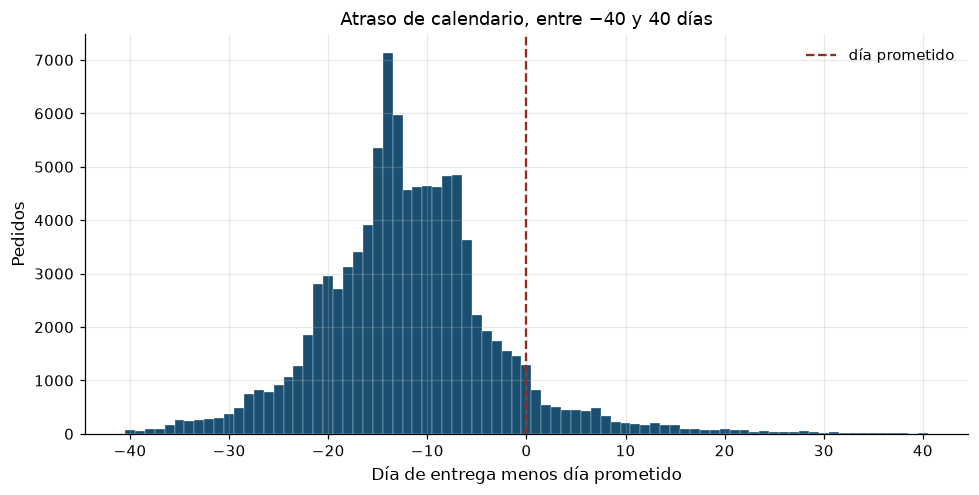

De **96,476** entregas fechadas, **91.9%** llegaron antes del día prometido, **1.3%** ese día y **6.8%** después. La mediana de todos los atrasos es **-12** días. Entre las **6,535** tardías, la mediana es **7** días, la media **10.6** y el percentil 90 es **22**. Fuera de la ventana del histograma quedan **532** pedidos a la izquierda y **194** a la derecha.

In [4]:
parte_antes = float(fechados["atraso_dias"].lt(0).mean())
parte_dia = float(fechados["atraso_dias"].eq(0).mean())
parte_tarde = float(fechados["tarde"].mean())
tarde = fechados.loc[fechados["tarde"]]
fuera_izq = int(fechados["atraso_dias"].lt(-40).sum())
fuera_der = int(fechados["atraso_dias"].gt(40).sum())

fig, ax = figura(
    "Atraso de calendario, entre −40 y 40 días",
    "Día de entrega menos día prometido",
    "Pedidos",
)
ax.hist(
    fechados.loc[fechados["atraso_dias"].between(-40, 40), "atraso_dias"],
    bins=np.arange(-40.5, 41.5, 1),
    color="#1b4f72",
    edgecolor="white",
    linewidth=0.2,
)
ax.axvline(0, color="#922b21", linestyle="--", label="día prometido")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

display(Markdown(
    f"De **{len(fechados):,}** entregas fechadas, **{parte_antes:.1%}** llegaron antes del día prometido, "
    f"**{parte_dia:.1%}** ese día y **{parte_tarde:.1%}** después. "
    f"La mediana de todos los atrasos es **{fechados['atraso_dias'].median():.0f}** días. "
    f"Entre las **{len(tarde):,}** tardías, la mediana es **{tarde['atraso_dias'].median():.0f}** días, "
    f"la media **{tarde['atraso_dias'].mean():.1f}** y el percentil 90 es **{tarde['atraso_dias'].quantile(0.9):.0f}**. "
    f"Fuera de la ventana del histograma quedan **{fuera_izq:,}** pedidos a la izquierda y **{fuera_der:,}** a la derecha."
))


La primera gráfica parte la espera en aprobación del pago, entrega al transportista y tránsito. Entra un pedido solo si esas tres fechas van en orden. El tramo largo está después de que el vendedor soltó el paquete. La mediana del tránsito en la tabla usa las filas en las que la compra precede al transportista y este al cliente.


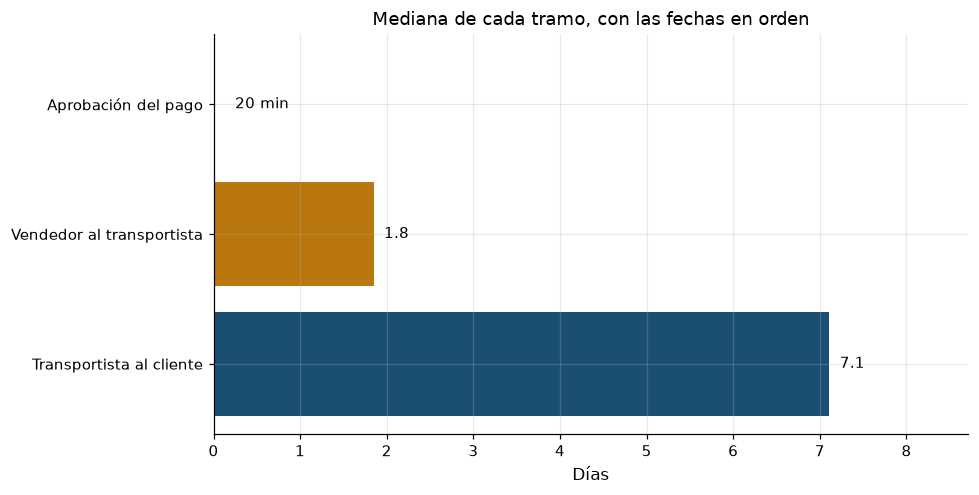

,pedidos,mediana_hasta_transportista,mediana_transito,mediana_espera,mediana_atraso
tarde,,,,,
En el día o antes,89755,2.15,6.95,9.82,-13.0
Tarde,6532,3.50,26.20,31.25,7.0


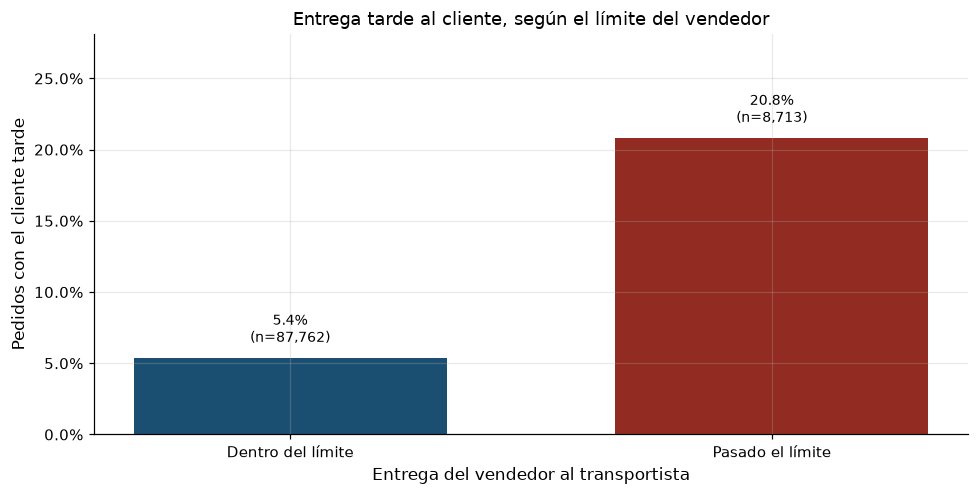

En **96,475** pedidos con límite y con entrega al transportista, el vendedor se pasa de ese límite en **9.0%**. Si lo cumplió, el cliente llega tarde el **5.4%** de las veces; si no lo cumplió, el **20.8%**. Entre los clientes que llegan tarde, el vendedor había cumplido el límite en **72%**. Las medianas de arriba dejan fuera **188** pedidos cuyo reloj no está en orden.

In [5]:
en_orden = fechados.loc[
    fechados["order_approved_at"].notna() & fechados["order_delivered_carrier_date"].notna()
].copy()
en_orden["tramo_aprobacion"] = (
    en_orden["order_approved_at"] - en_orden["order_purchase_timestamp"]
).dt.total_seconds() / 86400
en_orden["tramo_vendedor"] = (
    en_orden["order_delivered_carrier_date"] - en_orden["order_approved_at"]
).dt.total_seconds() / 86400
en_orden["tramo_transito"] = (
    en_orden["order_delivered_customer_date"] - en_orden["order_delivered_carrier_date"]
).dt.total_seconds() / 86400
en_orden = en_orden.loc[
    en_orden["tramo_aprobacion"].ge(0)
    & en_orden["tramo_vendedor"].ge(0)
    & en_orden["tramo_transito"].ge(0)
]
TRAMOS = ["tramo_aprobacion", "tramo_vendedor", "tramo_transito"]
NOMBRE_TRAMO = {
    "tramo_aprobacion": "Aprobación del pago",
    "tramo_vendedor": "Vendedor al transportista",
    "tramo_transito": "Transportista al cliente",
}
mediana_tramo = en_orden[TRAMOS].median().rename(index=NOMBRE_TRAMO).iloc[::-1]
fig, ax = figura("Mediana de cada tramo, con las fechas en orden", "Días", "")
barras = ax.barh(mediana_tramo.index, mediana_tramo, color=["#1b4f72", "#b9770e", "#0e6655"])
for barra, valor in zip(barras, mediana_tramo):
    if valor < 0.2:
        texto = f"{valor * 24 * 60:.0f} min"
        xpos = 0.25
    else:
        texto = f"{valor:.1f}"
        xpos = valor + 0.12
    ax.text(xpos, barra.get_y() + barra.get_height() / 2, texto, va="center", fontsize=10)
ax.set_xlim(0, mediana_tramo.max() + 1.6)
fig.tight_layout()
plt.show()

despacho = fechados[
    fechados["limite_despacho"].notna() & fechados["order_delivered_carrier_date"].notna()
].copy()
cronologico = despacho[
    despacho["order_delivered_carrier_date"].ge(despacho["order_purchase_timestamp"])
    & despacho["order_delivered_customer_date"].ge(despacho["order_delivered_carrier_date"])
].copy()
cronologico["transito_dias"] = (
    cronologico["order_delivered_customer_date"] - cronologico["order_delivered_carrier_date"]
).dt.total_seconds() / 86400
cronologico["hasta_transportista_dias"] = (
    cronologico["order_delivered_carrier_date"] - cronologico["order_purchase_timestamp"]
).dt.total_seconds() / 86400

resumen_tramo = cronologico.groupby("tarde").agg(
    pedidos=("order_id", "size"),
    mediana_hasta_transportista=("hasta_transportista_dias", "median"),
    mediana_transito=("transito_dias", "median"),
    mediana_espera=("espera_dias", "median"),
    mediana_atraso=("atraso_dias", "median"),
)
resumen_tramo.index = resumen_tramo.index.map({False: "En el día o antes", True: "Tarde"})
display(resumen_tramo.round(2))

tasa_vendedor = despacho.groupby("vendedor_tarde").agg(
    pedidos=("order_id", "size"),
    tasa_cliente_tarde=("tarde", "mean"),
)
tasa_vendedor.index = tasa_vendedor.index.map({False: "Dentro del límite", True: "Pasado el límite"})

fig, ax = figura(
    "Entrega tarde al cliente, según el límite del vendedor",
    "Entrega del vendedor al transportista",
    "Pedidos con el cliente tarde",
)
barras = ax.bar(
    tasa_vendedor.index.astype(str),
    tasa_vendedor["tasa_cliente_tarde"],
    color=["#1b4f72", "#922b21"],
    width=0.65,
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, tasa_vendedor["tasa_cliente_tarde"].max() * 1.35)
for barra, (_, fila) in zip(barras, tasa_vendedor.iterrows()):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.008,
        f"{fila['tasa_cliente_tarde']:.1%}\n(n={int(fila['pedidos']):,})",
        ha="center",
        va="bottom",
        fontsize=9,
    )
fig.tight_layout()
plt.show()

parte_vendedor_tarde = float(despacho["vendedor_tarde"].mean())
vendedor_entre_clientes_tarde = float(despacho.loc[despacho["tarde"], "vendedor_tarde"].mean())
display(Markdown(
    f"En **{len(despacho):,}** pedidos con límite y con entrega al transportista, "
    f"el vendedor se pasa de ese límite en **{parte_vendedor_tarde:.1%}**. "
    f"Si lo cumplió, el cliente llega tarde el **{tasa_vendedor.loc['Dentro del límite', 'tasa_cliente_tarde']:.1%}** de las veces; "
    f"si no lo cumplió, el **{tasa_vendedor.loc['Pasado el límite', 'tasa_cliente_tarde']:.1%}**. "
    f"Entre los clientes que llegan tarde, el vendedor había cumplido el límite en **{1 - vendedor_entre_clientes_tarde:.0%}**. "
    f"Las medianas de arriba dejan fuera **{len(despacho) - len(cronologico):,}** pedidos cuyo reloj no está en orden."
))


## 5. La nota se une al pedido

La nota va de 1 a 5. Las tres situaciones de abajo no se solapan. «Tarde» es un día posterior al prometido. «En el día o antes» incluye el día prometido.


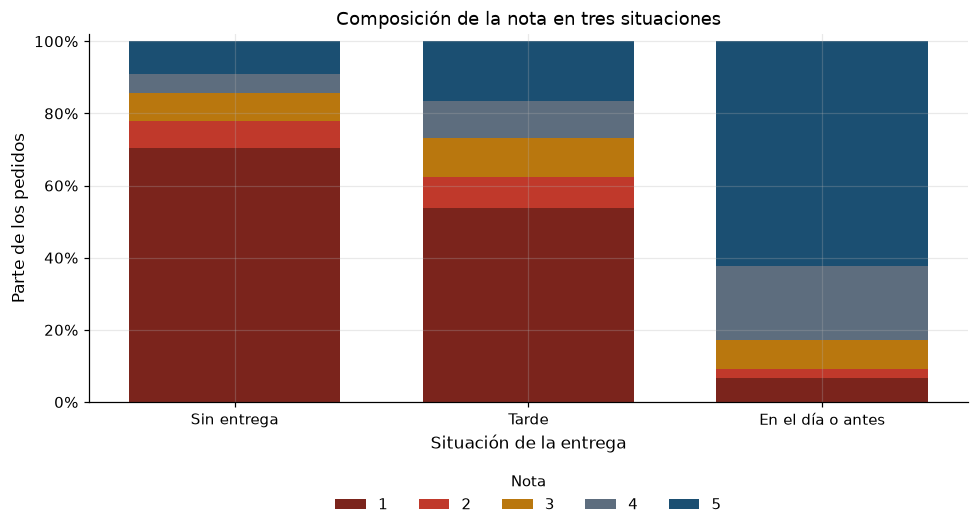

,pedidos,nota media,"notas 1 o 2, %","notas 5, %"
situación,,,,
Sin entrega,2835,1.75,77.9,9.0
Tarde,6382,2.27,62.3,16.6
En el día o antes,89448,4.29,9.3,62.3


Un pedido sin entrega promedia **1.75**. Uno tarde, **2.27**. Uno en el día prometido o antes, **4.29**. Las notas 1 y 2 son el **78%**, el **62%** y el **9%** de cada grupo.

El reloj llamaría tarde a las **1,280** entregas del día prometido. Su nota media es **4.04**, junto a las entregas anticipadas.

In [6]:
def distribucion(df):
    return df["nota"].value_counts(normalize=True).reindex([1, 2, 3, 4, 5]).fillna(0.0)


grupos_nota = [
    ("Sin entrega", sin_entrega),
    ("Tarde", con_nota.loc[con_nota["tarde"]]),
    ("En el día o antes", con_nota.loc[~con_nota["tarde"]]),
]
colores_nota = {1: "#7b241c", 2: "#c0392b", 3: "#b9770e", 4: "#5d6d7e", 5: "#1b4f72"}

fig, ax = figura(
    "Composición de la nota en tres situaciones",
    "Situación de la entrega",
    "Parte de los pedidos",
    alto=5.0,
)
fondo = np.zeros(len(grupos_nota))
posiciones = np.arange(len(grupos_nota))
for puntaje, color in colores_nota.items():
    alturas = [float(distribucion(df).loc[puntaje]) for _, df in grupos_nota]
    ax.bar(posiciones, alturas, bottom=fondo, color=color, width=0.72, label=str(puntaje))
    fondo = fondo + alturas
ax.set_xticks(posiciones)
ax.set_xticklabels([nombre for nombre, _ in grupos_nota])
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(
    title="Nota", frameon=False, ncol=5,
    loc="upper center", bbox_to_anchor=(0.5, -0.16),
)
fig.tight_layout()
plt.show()

filas_grupos = []
for nombre, df in grupos_nota:
    filas_grupos.append({
        "situación": nombre,
        "pedidos": len(df),
        "nota_media": df["nota"].mean(),
        "nota_1_o_2": df["nota"].le(2).mean(),
        "nota_5": df["nota"].eq(5).mean(),
    })
tabla_grupos = pd.DataFrame(filas_grupos).set_index("situación")
display(tabla_grupos.assign(
    nota_media=lambda d: d["nota_media"].round(2),
    nota_1_o_2=lambda d: (d["nota_1_o_2"] * 100).round(1),
    nota_5=lambda d: (d["nota_5"] * 100).round(1),
).rename(columns={"nota_1_o_2": "notas 1 o 2, %", "nota_5": "notas 5, %", "nota_media": "nota media"}))

mismo_dia = con_nota.loc[con_nota["atraso_dias"].eq(0)]
display(Markdown(
    f"Un pedido sin entrega promedia **{tabla_grupos.loc['Sin entrega', 'nota_media']:.2f}**. "
    f"Uno tarde, **{tabla_grupos.loc['Tarde', 'nota_media']:.2f}**. "
    f"Uno en el día prometido o antes, **{tabla_grupos.loc['En el día o antes', 'nota_media']:.2f}**. "
    f"Las notas 1 y 2 son el **{tabla_grupos.loc['Sin entrega', 'nota_1_o_2']:.0%}**, "
    f"el **{tabla_grupos.loc['Tarde', 'nota_1_o_2']:.0%}** y el **{tabla_grupos.loc['En el día o antes', 'nota_1_o_2']:.0%}** de cada grupo.\n\n"
    f"El reloj llamaría tarde a las **{len(mismo_dia):,}** entregas del día prometido. "
    f"Su nota media es **{mismo_dia['nota'].mean():.2f}**, junto a las entregas anticipadas."
))


La nota no cae de golpe en el primer día de adelanto. Cae al pasar el día prometido, y sigue más baja cuando el atraso ya se cuenta por semanas.


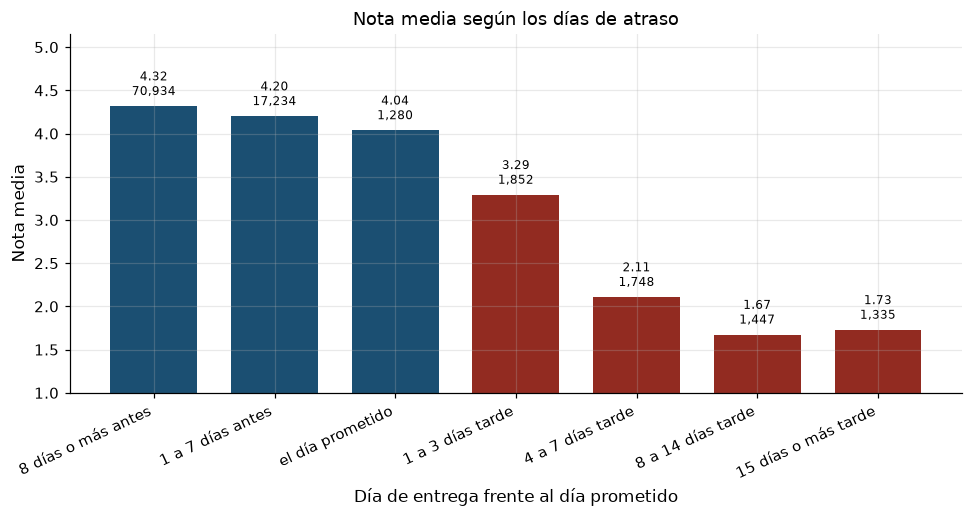

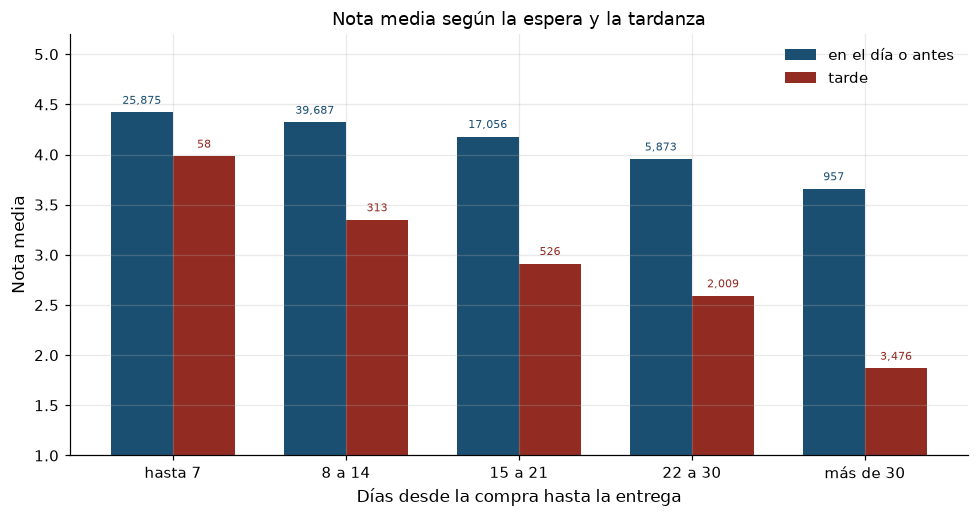

Ocho días o más de adelanto quedan en **4.32**. El día prometido, en **4.04**. Uno a tres días tarde, en **3.29**. De ocho días tarde en adelante, la media queda cerca de **1.67**.

Una espera de más de 30 días que cumple el día prometido promedia **3.66**. La misma espera, tarde, promedia **1.87**. La espera corta y a tiempo promedia **4.42**: esperar también mueve la nota. La barra tarde de la primera semana apoya en **58** pedidos. Una promesa de varias semanas casi no se vence en los primeros siete días.

In [7]:
por_tramo = con_nota.groupby("tramo_atraso", observed=True).agg(
    pedidos=("order_id", "size"),
    nota=("nota", "mean"),
)
por_tramo = por_tramo.reindex(ETIQ_ATRASO)

fig, ax = figura(
    "Nota media según los días de atraso",
    "Día de entrega frente al día prometido",
    "Nota media",
    alto=4.8,
)
colores_tramo = ["#1b4f72" if i < 3 else "#922b21" for i in range(len(por_tramo))]
barras = ax.bar(np.arange(len(por_tramo)), por_tramo["nota"], color=colores_tramo, width=0.72)
ax.set_xticks(np.arange(len(por_tramo)))
ax.set_xticklabels(por_tramo.index.astype(str), rotation=25, ha="right")
ax.set_ylim(1, 5.15)
for i, (_, fila) in enumerate(por_tramo.iterrows()):
    ax.text(i, fila["nota"] + 0.08, f"{fila['nota']:.2f}\n{int(fila['pedidos']):,}", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
plt.show()

por_espera = con_nota.pivot_table(
    index="tramo_espera",
    columns="tarde",
    values="nota",
    aggfunc=["mean", "count"],
    observed=True,
).reindex(ETIQ_ESPERA)

fig, ax = figura(
    "Nota media según la espera y la tardanza",
    "Días desde la compra hasta la entrega",
    "Nota media",
    alto=4.8,
)
posiciones = np.arange(len(ETIQ_ESPERA))
ax.bar(posiciones - 0.18, por_espera[("mean", False)], width=0.36, color="#1b4f72", label="en el día o antes")
ax.bar(posiciones + 0.18, por_espera[("mean", True)], width=0.36, color="#922b21", label="tarde")
for i, tramo in enumerate(ETIQ_ESPERA):
    ax.text(i - 0.18, por_espera.loc[tramo, ("mean", False)] + 0.06, f"{int(por_espera.loc[tramo, ('count', False)]):,}", ha="center", va="bottom", fontsize=7, color="#1b4f72")
    ax.text(i + 0.18, por_espera.loc[tramo, ("mean", True)] + 0.06, f"{int(por_espera.loc[tramo, ('count', True)]):,}", ha="center", va="bottom", fontsize=7, color="#922b21")
ax.set_xticks(posiciones)
ax.set_xticklabels(ETIQ_ESPERA)
ax.set_ylim(1, 5.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

espera_larga_a_tiempo = float(por_espera.loc["más de 30", ("mean", False)])
espera_larga_tarde = float(por_espera.loc["más de 30", ("mean", True)])
espera_corta_a_tiempo = float(por_espera.loc["hasta 7", ("mean", False)])
display(Markdown(
    f"Ocho días o más de adelanto quedan en **{por_tramo.loc['8 días o más antes', 'nota']:.2f}**. "
    f"El día prometido, en **{por_tramo.loc['el día prometido', 'nota']:.2f}**. "
    f"Uno a tres días tarde, en **{por_tramo.loc['1 a 3 días tarde', 'nota']:.2f}**. "
    f"De ocho días tarde en adelante, la media queda cerca de **{por_tramo.loc['8 a 14 días tarde', 'nota']:.2f}**.\n\n"
    f"Una espera de más de 30 días que cumple el día prometido promedia **{espera_larga_a_tiempo:.2f}**. "
    f"La misma espera, tarde, promedia **{espera_larga_tarde:.2f}**. "
    f"La espera corta y a tiempo promedia **{espera_corta_a_tiempo:.2f}**: esperar también mueve la nota. "
    f"La barra tarde de la primera semana apoya en **{int(por_espera.loc['hasta 7', ('count', True)])}** pedidos. "
    "Una promesa de varias semanas casi no se vence en los primeros siete días."
))


## 6. La encuesta llega mientras el paquete tarde sigue en camino

`review_creation_date` es el día en que se envía la encuesta. `review_answer_timestamp` es el momento en que el cliente responde. En un pedido a tiempo, esa encuesta cae junto a la entrega. En un pedido tarde, cae junto al día prometido, antes de que el paquete llegue. La respuesta anterior a la entrega es la forma que toma el atraso en la nota, no un segundo fenómeno suelto.


,"encuesta menos entrega, días","encuesta menos promesa, días",respondió antes de la entrega
En el día o antes,1.0,-12.0,0.003
Tarde,-4.0,2.0,0.702


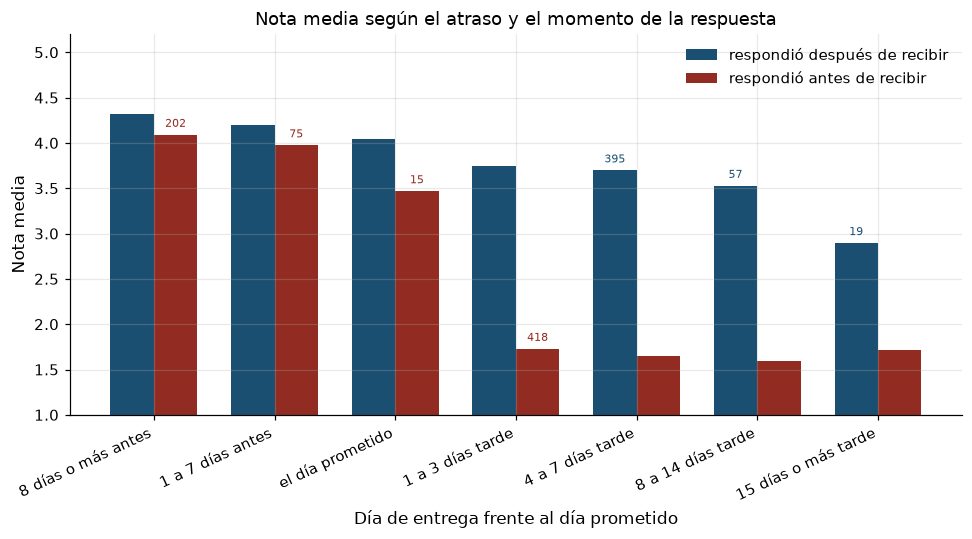

,"n, después","nota, después","n, antes","nota, antes"
tramo_atraso,,,,
8 días o más antes,70732,4.32,202,4.09
1 a 7 días antes,17159,4.20,75,3.97
el día prometido,1265,4.04,15,3.47
1 a 3 días tarde,1434,3.75,418,1.73
4 a 7 días tarde,395,3.70,1353,1.64
8 a 14 días tarde,57,3.53,1390,1.60
15 días o más tarde,19,2.89,1316,1.71


En un pedido a tiempo, la mediana de la encuesta queda **1 día después** de la entrega y **12 días antes** de la promesa. En un pedido tarde, queda **4 días antes** de la entrega y **2 días después** de la promesa. El número sobre una barra es la cantidad de pedidos cuando esa barra tiene menos de 500.

Responde antes de recibir el paquete el **70%** de los pedidos tarde y el **0.3%** de los que van en el día o antes. Esas respuestas tempranas, en el grupo tarde, promedian **1.66**. Las que llegan después del paquete tarde promedian **3.72**. En los atrasos de ocho días o más, la columna «después» queda en unas decenas de pedidos: casi todo el grupo ya contestó antes de recibir.

In [8]:
a_tiempo = con_nota.loc[~con_nota["tarde"]]
tarde_nota = con_nota.loc[con_nota["tarde"]]
mediana_encuesta = pd.DataFrame({
    "encuesta menos entrega, días": [
        a_tiempo["encuesta_menos_entrega"].median(),
        tarde_nota["encuesta_menos_entrega"].median(),
    ],
    "encuesta menos promesa, días": [
        a_tiempo["encuesta_menos_promesa"].median(),
        tarde_nota["encuesta_menos_promesa"].median(),
    ],
    "respondió antes de la entrega": [
        a_tiempo["respondio_antes"].mean(),
        tarde_nota["respondio_antes"].mean(),
    ],
}, index=["En el día o antes", "Tarde"])
display(mediana_encuesta.round(3))

por_respuesta = con_nota.groupby(["tramo_atraso", "respondio_antes"], observed=True).agg(
    pedidos=("order_id", "size"),
    nota=("nota", "mean"),
).reset_index()

fig, ax = figura(
    "Nota media según el atraso y el momento de la respuesta",
    "Día de entrega frente al día prometido",
    "Nota media",
    alto=5.0,
)
posiciones = np.arange(len(ETIQ_ATRASO))
for desplazamiento, valor, color, leyenda in (
    (-0.18, False, "#1b4f72", "respondió después de recibir"),
    (0.18, True, "#922b21", "respondió antes de recibir"),
):
    sub = por_respuesta.loc[por_respuesta["respondio_antes"].eq(valor)].set_index("tramo_atraso").reindex(ETIQ_ATRASO)
    ax.bar(posiciones + desplazamiento, sub["nota"], width=0.36, color=color, label=leyenda)
    for i, (cantidad, nota) in enumerate(zip(sub["pedidos"], sub["nota"])):
        if pd.notna(cantidad) and cantidad < 500 and pd.notna(nota):
            ax.text(i + desplazamiento, nota + 0.06, f"{int(cantidad)}", ha="center", va="bottom", fontsize=7, color=color)
ax.set_xticks(posiciones)
ax.set_xticklabels(ETIQ_ATRASO, rotation=25, ha="right")
ax.set_ylim(1, 5.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

tabla_respuesta = pd.DataFrame({
    "n, después": por_respuesta.loc[~por_respuesta["respondio_antes"].astype(bool)].set_index("tramo_atraso").reindex(ETIQ_ATRASO)["pedidos"],
    "nota, después": por_respuesta.loc[~por_respuesta["respondio_antes"].astype(bool)].set_index("tramo_atraso").reindex(ETIQ_ATRASO)["nota"],
    "n, antes": por_respuesta.loc[por_respuesta["respondio_antes"].astype(bool)].set_index("tramo_atraso").reindex(ETIQ_ATRASO)["pedidos"],
    "nota, antes": por_respuesta.loc[por_respuesta["respondio_antes"].astype(bool)].set_index("tramo_atraso").reindex(ETIQ_ATRASO)["nota"],
})
display(tabla_respuesta.assign(**{
    "nota, después": tabla_respuesta["nota, después"].round(2),
    "nota, antes": tabla_respuesta["nota, antes"].round(2),
}))

def en_dias(valor):
    entero = int(abs(valor))
    return f"{entero} día" if entero == 1 else f"{entero} días"


nota_tarde_antes = float(tarde_nota.loc[tarde_nota["respondio_antes"], "nota"].mean())
nota_tarde_despues = float(tarde_nota.loc[~tarde_nota["respondio_antes"], "nota"].mean())
display(Markdown(
    f"En un pedido a tiempo, la mediana de la encuesta queda **{en_dias(a_tiempo['encuesta_menos_entrega'].median())} después** "
    f"de la entrega y **{en_dias(a_tiempo['encuesta_menos_promesa'].median())} antes** de la promesa. "
    f"En un pedido tarde, queda **{en_dias(tarde_nota['encuesta_menos_entrega'].median())} antes** de la entrega "
    f"y **{en_dias(tarde_nota['encuesta_menos_promesa'].median())} después** de la promesa. "
    "El número sobre una barra es la cantidad de pedidos cuando esa barra tiene menos de 500.\n\n"
    f"Responde antes de recibir el paquete el **{tarde_nota['respondio_antes'].mean():.0%}** de los pedidos tarde "
    f"y el **{a_tiempo['respondio_antes'].mean():.1%}** de los que van en el día o antes. "
    f"Esas respuestas tempranas, en el grupo tarde, promedian **{nota_tarde_antes:.2f}**. "
    f"Las que llegan después del paquete tarde promedian **{nota_tarde_despues:.2f}**. "
    "En los atrasos de ocho días o más, la columna «después» queda en unas decenas de pedidos: "
    "casi todo el grupo ya contestó antes de recibir."
))


## 7. Qué más baja la nota, y qué casi no la mueve

Las brechas de abajo son diferencias de nota media. El flete y el precio se miran dentro de São Paulo, con un solo artículo y con la entrega en el día prometido o antes, para no mezclarlos con la distancia ni con el atraso. La categoría usa el nombre en inglés de la traducción y pide al menos 500 pedidos a tiempo. El diccionario es una criba de palabras, no una lectura del comentario.


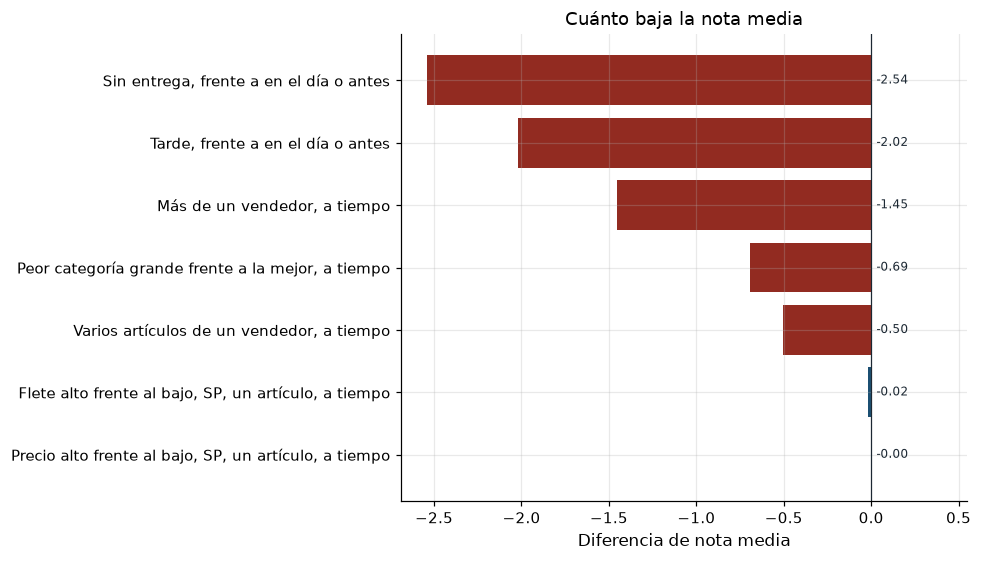

,correlación con la nota
"Espera, días",-0.334
"Atraso de calendario, días",-0.266
"Atraso, Spearman",-0.176
Artículos del pedido,-0.124
"Flete, BRL",-0.089
"Precio, BRL",-0.035


Más de un vendedor, con la entrega a tiempo, promedia **2.86** en **1,249** pedidos, frente a **4.31** con un solo vendedor. Su tasa de atraso es **1.0%**: la brecha no es el día prometido. La reseña es una sola para todo el pedido y no dice cuál vendedor falló.

Varios artículos de un mismo vendedor, a tiempo, promedian **3.85** (7,788 pedidos) frente a **4.36** de un solo artículo.

Entre las categorías con al menos 500 entregas a tiempo, **office furniture** promedia **3.77** y **luggage accessories** promedia **4.46**. En São Paulo, un artículo y a tiempo, el cuartil de flete más alto difiere del más bajo en **-0.02** puntos de nota, y el de precio en **-0.00**. Pearson del atraso con la nota es **-0.27** y Spearman **-0.18**. La correlación es más chica que el salto del gráfico anterior: la mayoría de los pedidos llega antes y ya tiene una nota alta.

In [9]:
sp = con_nota.loc[
    ~con_nota["tarde"]
    & con_nota["customer_state"].eq("SP")
    & con_nota["n_items"].eq(1)
    & con_nota["flete"].notna()
    & con_nota["precio"].notna()
].copy()
cuartil_flete = sp.groupby(pd.qcut(sp["flete"], 4), observed=True)["nota"].mean()
cuartil_precio = sp.groupby(pd.qcut(sp["precio"], 4), observed=True)["nota"].mean()
brecha_flete = float(cuartil_flete.iloc[-1] - cuartil_flete.iloc[0])
brecha_precio = float(cuartil_precio.iloc[-1] - cuartil_precio.iloc[0])

un_vendedor_un_item = con_nota.loc[~con_nota["tarde"] & con_nota["n_items"].eq(1) & con_nota["n_vendedores"].eq(1), "nota"]
varios_items = con_nota.loc[~con_nota["tarde"] & con_nota["n_items"].gt(1) & con_nota["n_vendedores"].eq(1), "nota"]
varios_vendedores = con_nota.loc[~con_nota["tarde"] & con_nota["n_vendedores"].gt(1), "nota"]
un_vendedor = con_nota.loc[~con_nota["tarde"] & con_nota["n_vendedores"].eq(1), "nota"]

categorias = (
    con_nota.loc[~con_nota["tarde"]]
    .groupby("categoria", observed=True)["nota"]
    .agg(["count", "mean"])
)
categorias = categorias.loc[categorias["count"].ge(500)].sort_values("mean")
peor_categoria = str(categorias.index[0]).replace("_", " ")
mejor_categoria = str(categorias.index[-1]).replace("_", " ")
brecha_categoria = float(categorias["mean"].iloc[0] - categorias["mean"].iloc[-1])

brechas = pd.Series({
    "Sin entrega, frente a en el día o antes": sin_entrega["nota"].mean() - a_tiempo["nota"].mean(),
    "Tarde, frente a en el día o antes": tarde_nota["nota"].mean() - a_tiempo["nota"].mean(),
    "Más de un vendedor, a tiempo": varios_vendedores.mean() - un_vendedor.mean(),
    "Varios artículos de un vendedor, a tiempo": varios_items.mean() - un_vendedor_un_item.mean(),
    "Peor categoría grande frente a la mejor, a tiempo": brecha_categoria,
    "Flete alto frente al bajo, SP, un artículo, a tiempo": brecha_flete,
    "Precio alto frente al bajo, SP, un artículo, a tiempo": brecha_precio,
}).sort_values()

fig, ax = figura(
    "Cuánto baja la nota media",
    "Diferencia de nota media",
    "",
    alto=5.2,
)
ordenado = brechas.sort_values(ascending=False)
colores = ["#922b21" if valor < -0.4 else "#1b4f72" for valor in ordenado]
ax.barh(ordenado.index.astype(str), ordenado.to_numpy(), color=colores)
for y, valor in enumerate(ordenado.to_numpy()):
    ax.text(0.03, y, f"{valor:+.2f}", va="center", ha="left", fontsize=8, color="#1c2833")
ax.axvline(0, color="#1c2833", linewidth=0.8)
ax.set_xlim(ordenado.min() - 0.15, 0.55)
fig.tight_layout()
plt.show()

correlaciones = pd.Series({
    "Espera, días": con_nota["espera_dias"].corr(con_nota["nota"]),
    "Atraso de calendario, días": con_nota["atraso_dias"].corr(con_nota["nota"]),
    "Atraso, Spearman": con_nota["atraso_dias"].corr(con_nota["nota"], method="spearman"),
    "Artículos del pedido": con_nota["n_items"].corr(con_nota["nota"]),
    "Flete, BRL": con_nota["flete"].corr(con_nota["nota"]),
    "Precio, BRL": con_nota["precio"].corr(con_nota["nota"]),
}, name="correlación con la nota")
display(correlaciones.round(3).to_frame())

display(Markdown(
    f"Más de un vendedor, con la entrega a tiempo, promedia **{varios_vendedores.mean():.2f}** "
    f"en **{len(varios_vendedores):,}** pedidos, frente a **{un_vendedor.mean():.2f}** con un solo vendedor. "
    f"Su tasa de atraso es **{con_nota.loc[con_nota['n_vendedores'].gt(1), 'tarde'].mean():.1%}**: "
    "la brecha no es el día prometido. La reseña es una sola para todo el pedido y no dice cuál vendedor falló.\n\n"
    f"Varios artículos de un mismo vendedor, a tiempo, promedian **{varios_items.mean():.2f}** "
    f"({len(varios_items):,} pedidos) frente a **{un_vendedor_un_item.mean():.2f}** de un solo artículo.\n\n"
    f"Entre las categorías con al menos 500 entregas a tiempo, "
    f"**{peor_categoria}** promedia **{categorias['mean'].iloc[0]:.2f}** y **{mejor_categoria}** promedia **{categorias['mean'].iloc[-1]:.2f}**. "
    f"En São Paulo, un artículo y a tiempo, el cuartil de flete más alto difiere del más bajo en **{brecha_flete:+.2f}** puntos de nota, "
    f"y el de precio en **{brecha_precio:+.2f}**. "
    f"Pearson del atraso con la nota es **{correlaciones.loc['Atraso de calendario, días']:.2f}** "
    f"y Spearman **{correlaciones.loc['Atraso, Spearman']:.2f}**. "
    "La correlación es más chica que el salto del gráfico anterior: la mayoría de los pedidos llega antes y ya tiene una nota alta."
))


In [10]:
PAT_ATRASO = (
    r"atras|demor|nao chegou|nao recebi|nao entreg|"
    r"ainda nao|nao veio|nunca chegou|fora do prazo|depois do prazo"
)
PAT_PRODUCTO = (
    r"defeito|quebr|errad|faltand|faltou|incomplet|avaria|danific|"
    r"nao funciona|veio outro|produto errado|diferente do"
)


def sin_acentos(serie):
    return (
        serie.fillna("")
        .str.lower()
        .str.normalize("NFKD")
        .str.encode("ascii", "ignore")
        .str.decode("ascii")
    )


def marcar_texto(df):
    texto = sin_acentos(df["mensajes"]) + " " + sin_acentos(df["titulos"])
    salida = df.copy()
    salida["menciona_atraso"] = texto.str.contains(PAT_ATRASO, regex=True)
    salida["menciona_producto"] = texto.str.contains(PAT_PRODUCTO, regex=True)
    return salida


marcados = marcar_texto(con_nota)
sin_marcado = marcar_texto(sin_entrega)
baja_tarde = marcados.loc[marcados["tarde"] & marcados["nota"].le(2)]
baja_a_tiempo = marcados.loc[~marcados["tarde"] & marcados["nota"].le(2)]
baja_sin = sin_marcado.loc[sin_marcado["nota"].le(2)]
nota_cinco = marcados.loc[marcados["nota"].eq(5)]

filas_texto = []
for nombre, df in (
    ("Tarde y nota 1 o 2", baja_tarde),
    ("A tiempo y nota 1 o 2", baja_a_tiempo),
    ("Sin entrega y nota 1 o 2", baja_sin),
    ("Nota 5, con fecha", nota_cinco),
):
    filas_texto.append({
        "grupo": nombre,
        "pedidos": len(df),
        "con texto": df["tiene_texto"].mean(),
        "menciona el atraso": df["menciona_atraso"].mean(),
        "menciona el producto": df["menciona_producto"].mean(),
    })
tabla_texto = pd.DataFrame(filas_texto).set_index("grupo")
display(tabla_texto.assign(**{
    "con texto": (tabla_texto["con texto"] * 100).round(1),
    "menciona el atraso": (tabla_texto["menciona el atraso"] * 100).round(1),
    "menciona el producto": (tabla_texto["menciona el producto"] * 100).round(1),
}))


def ejemplo(df, columna):
    textos = (
        df.loc[df[columna], "mensajes"]
        .dropna()
        .astype(str)
        .map(lambda texto: " ".join(texto.split()))
    )
    textos = textos[textos.str.len().between(40, 160) & ~textos.str.contains("[äÃÂ�]", regex=True)]
    if textos.empty:
        return ""
    return textos.iloc[0]


display(Markdown(
    "Entre las notas 1 y 2 de un pedido tarde, el texto habla del plazo con más frecuencia que del producto. "
    "Entre las notas 1 y 2 de un pedido a tiempo, la relación se invierte. "
    f"En las notas 5 el diccionario de atraso se activa en el **{nota_cinco['menciona_atraso'].mean():.1%}**: "
    "esa cifra es una cota del ruido, porque una nota 5 también puede mencionar una demora de otro pedido "
    "o agradecer que llegó pronto.\n\n"
    f"Ejemplo tarde: «{ejemplo(baja_tarde, 'menciona_atraso')}»\n\n"
    f"Ejemplo a tiempo: «{ejemplo(baja_a_tiempo, 'menciona_producto')}»\n\n"
    "Más de la mitad de las reseñas no trae mensaje. La ausencia de la palabra no es la ausencia de la queja."
))

bajas = pd.concat([
    con_nota.loc[con_nota["nota"].le(2), ["order_id", "tarde"]],
    sin_entrega.loc[sin_entrega["nota"].le(2), ["order_id"]].assign(tarde=pd.NA),
], ignore_index=True)
bajas["grupo_baja"] = "a tiempo"
bajas.loc[bajas["tarde"].isna(), "grupo_baja"] = "sin entrega"
bajas.loc[bajas["tarde"].eq(True), "grupo_baja"] = "tarde"
parte_bajas = bajas["grupo_baja"].value_counts(normalize=True)
display(Markdown(
    f"De **{len(bajas):,}** notas 1 o 2 en los tres grupos, "
    f"**{parte_bajas.get('a tiempo', 0):.0%}** son entregas en el día o antes, "
    f"**{parte_bajas.get('tarde', 0):.0%}** son tardías y "
    f"**{parte_bajas.get('sin entrega', 0):.0%}** no tienen entrega. "
    "El atraso baja la nota con fuerza y, aun así, la mayoría de las notas bajas pertenece a pedidos que llegaron a tiempo: "
    "esos pedidos son casi todos."
))


,pedidos,con texto,menciona el atraso,menciona el producto
grupo,,,,
Tarde y nota 1 o 2,3979,69.8,42.5,1.6
A tiempo y nota 1 o 2,8287,79.0,15.9,18.9
Sin entrega y nota 1 o 2,2209,72.9,35.8,2.3
"Nota 5, con fecha",56761,38.1,0.8,0.4


Entre las notas 1 y 2 de un pedido tarde, el texto habla del plazo con más frecuencia que del producto. Entre las notas 1 y 2 de un pedido a tiempo, la relación se invierte. En las notas 5 el diccionario de atraso se activa en el **0.8%**: esa cifra es una cota del ruido, porque una nota 5 también puede mencionar una demora de otro pedido o agradecer que llegó pronto.

Ejemplo tarde: «Demora muito entregar. Já passou o prazo e ainda não recebi minha encomenda.»

Ejemplo a tiempo: «A cuba veio quebrada. Como efetuo barroca?»

Más de la mitad de las reseñas no trae mensaje. La ausencia de la palabra no es la ausencia de la queja.

De **14,475** notas 1 o 2 en los tres grupos, **57%** son entregas en el día o antes, **27%** son tardías y **15%** no tienen entrega. El atraso baja la nota con fuerza y, aun así, la mayoría de las notas bajas pertenece a pedidos que llegaron a tiempo: esos pedidos son casi todos.

## 8. Donde sube el atraso, baja la nota

La serie mensual usa los pedidos fechados y con nota, y deja fuera los meses con menos de 500. El eje de la nota no empieza en cero: muestra el recorrido de las medias mensuales. El estado pide al menos 400 pedidos. El tamaño del punto sigue la cantidad de pedidos.


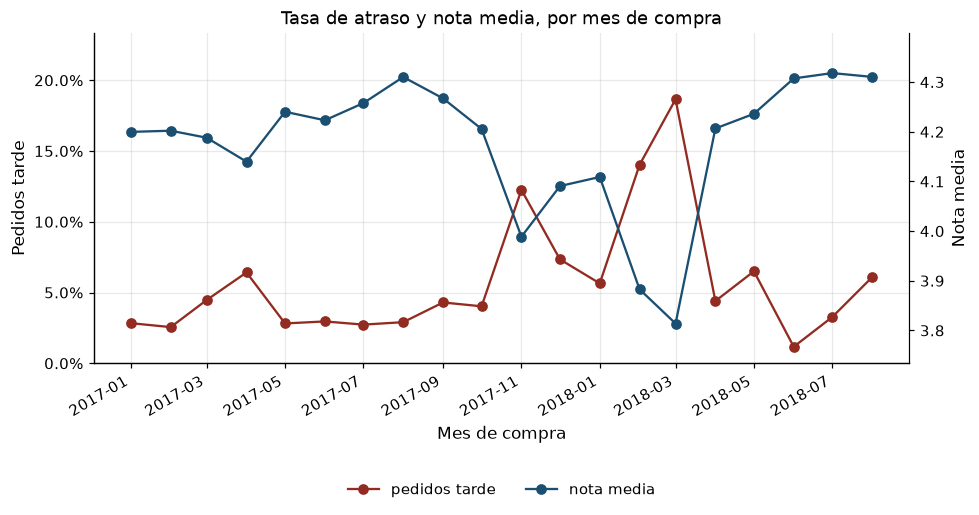

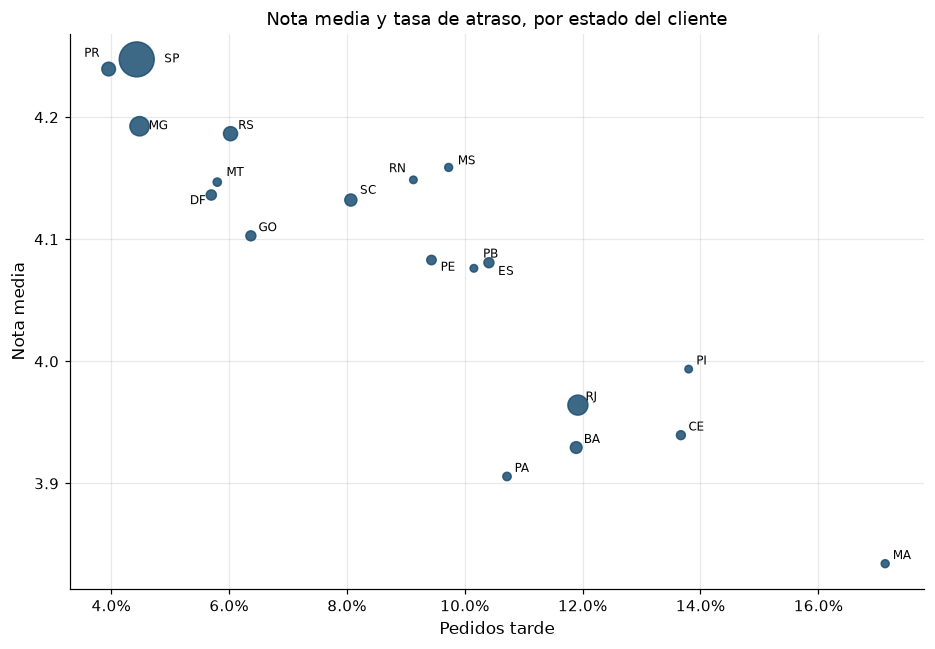

El mes con más atrasos es **2018-03** (**18.7%**, nota **3.81**). El de menos es **2018-06** (**1.2%**, nota **4.31**).

El día con más compras del extracto es el **24 de noviembre de 2017**. Del 23 al 26 de noviembre de 2017 la tardanza es **17.7%** (2,265 pedidos) y en el resto de ese mes es **9.8%**. La semana de compra con más atrasos, entre las de al menos 400 pedidos fechados, es la de **2018-02-26/2018-03-04** (**26.0%**, nota **3.58**).

En los **19** estados con al menos 400 pedidos, la correlación entre la tasa de atraso y la nota media es **-0.90**. **MA** tiene la tasa más alta (**17.1%**, nota **3.83**, espera mediana **19.1** días). **SP** está en **4.4%** de atrasos y nota **4.25**, con una espera mediana de **7.2** días. **RJ** espera **12.0** días, menos que varios estados del Norte y del Nordeste, y aun así su tardanza es **11.9%**.

In [11]:
por_mes = con_nota.groupby(con_nota["order_purchase_timestamp"].dt.to_period("M")).agg(
    pedidos=("order_id", "size"),
    tasa=("tarde", "mean"),
    nota=("nota", "mean"),
)
por_mes = por_mes.loc[por_mes["pedidos"].ge(500)].copy()
por_mes["fecha"] = por_mes.index.to_timestamp()

titulo_mes = "Tasa de atraso y nota media, por mes de compra"
FIGURAS.append(titulo_mes)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.set_title(titulo_mes)
ax.plot(por_mes["fecha"], por_mes["tasa"], color="#922b21", marker="o", label="pedidos tarde")
ax.set_ylabel("Pedidos tarde")
ax.set_xlabel("Mes de compra")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, max(0.22, float(por_mes["tasa"].max()) * 1.25))
ax2 = ax.twinx()
ax2.plot(por_mes["fecha"], por_mes["nota"], color="#1b4f72", marker="o", label="nota media")
ax2.set_ylabel("Nota media")
ax2.set_ylim(float(por_mes["nota"].min()) - 0.08, float(por_mes["nota"].max()) + 0.08)
ax2.grid(False)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(True)
lineas_1, etiquetas_1 = ax.get_legend_handles_labels()
lineas_2, etiquetas_2 = ax2.get_legend_handles_labels()
ax.legend(
    lineas_1 + lineas_2,
    etiquetas_1 + etiquetas_2,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.32),
    ncol=2,
)
fig.autofmt_xdate()
fig.tight_layout()
fig.subplots_adjust(bottom=0.30)
plt.show()

noviembre = con_nota.loc[
    con_nota["order_purchase_timestamp"].between("2017-11-01", "2017-11-30 23:59:59")
]
puente = noviembre["order_purchase_timestamp"].between("2017-11-23", "2017-11-26 23:59:59")
dia_pico = pedidos["order_purchase_timestamp"].dt.normalize().value_counts().idxmax()
meses_es = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]
dia_pico_texto = f"{dia_pico.day} de {meses_es[dia_pico.month - 1]} de {dia_pico.year}"
por_semana = con_nota.groupby(con_nota["order_purchase_timestamp"].dt.to_period("W-SUN")).agg(
    pedidos=("order_id", "size"),
    tasa=("tarde", "mean"),
    nota=("nota", "mean"),
)
por_semana = por_semana.loc[por_semana["pedidos"].ge(400)]
peor_semana = por_semana["tasa"].idxmax()

por_estado = con_nota.groupby("customer_state").agg(
    pedidos=("order_id", "size"),
    tasa=("tarde", "mean"),
    nota=("nota", "mean"),
    espera=("espera_dias", "median"),
)
por_estado = por_estado.loc[por_estado["pedidos"].ge(400)].copy()
correlacion_estado = float(por_estado["tasa"].corr(por_estado["nota"]))

fig, ax = figura(
    "Nota media y tasa de atraso, por estado del cliente",
    "Pedidos tarde",
    "Nota media",
    ancho=8.6,
    alto=6.0,
)
ax.scatter(
    por_estado["tasa"],
    por_estado["nota"],
    s=18 + por_estado["pedidos"] / 80,
    color="#1b4f72",
    alpha=0.85,
    zorder=3,
)
desplazamiento = {
    "SP": (18, -2), "PR": (-16, 8), "MG": (6, -2),
    "PB": (6, 7), "ES": (6, -8), "RN": (-16, 5), "MS": (6, 2),
    "DF": (-14, -6), "MT": (6, 4), "PE": (6, -7), "SC": (6, 4),
}
for estado, fila in por_estado.iterrows():
    ax.annotate(
        estado,
        (fila["tasa"], fila["nota"]),
        textcoords="offset points",
        xytext=desplazamiento.get(estado, (5, 3)),
        fontsize=8,
    )
ax.xaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
plt.show()

display(Markdown(
    f"El mes con más atrasos es **{por_mes['tasa'].idxmax()}** (**{por_mes['tasa'].max():.1%}**, nota **{por_mes.loc[por_mes['tasa'].idxmax(), 'nota']:.2f}**). "
    f"El de menos es **{por_mes['tasa'].idxmin()}** (**{por_mes['tasa'].min():.1%}**, nota **{por_mes.loc[por_mes['tasa'].idxmin(), 'nota']:.2f}**).\n\n"
    f"El día con más compras del extracto es el **{dia_pico_texto}**. "
    f"Del 23 al 26 de noviembre de 2017 la tardanza es **{noviembre.loc[puente, 'tarde'].mean():.1%}** "
    f"({int(puente.sum()):,} pedidos) y en el resto de ese mes es **{noviembre.loc[~puente, 'tarde'].mean():.1%}**. "
    f"La semana de compra con más atrasos, entre las de al menos 400 pedidos fechados, es la de **{peor_semana}** "
    f"(**{por_semana.loc[peor_semana, 'tasa']:.1%}**, nota **{por_semana.loc[peor_semana, 'nota']:.2f}**).\n\n"
    f"En los **{len(por_estado)}** estados con al menos 400 pedidos, la correlación entre la tasa de atraso y la nota media es **{correlacion_estado:.2f}**. "
    f"**{por_estado['tasa'].idxmax()}** tiene la tasa más alta (**{por_estado['tasa'].max():.1%}**, nota **{por_estado.loc[por_estado['tasa'].idxmax(), 'nota']:.2f}**, "
    f"espera mediana **{por_estado.loc[por_estado['tasa'].idxmax(), 'espera']:.1f}** días). "
    f"**SP** está en **{por_estado.loc['SP', 'tasa']:.1%}** de atrasos y nota **{por_estado.loc['SP', 'nota']:.2f}**, "
    f"con una espera mediana de **{por_estado.loc['SP', 'espera']:.1f}** días. "
    f"**RJ** espera **{por_estado.loc['RJ', 'espera']:.1f}** días, menos que varios estados del Norte y del Nordeste, "
    f"y aun así su tardanza es **{por_estado.loc['RJ', 'tasa']:.1%}**."
))


## 9. Lectura


In [12]:
display(Markdown(
    f"La fecha prometida es un día, guardado a medianoche en los **{len(pedidos):,}** pedidos. "
    f"De **{len(fechados):,}** entregas con fecha, **{parte_antes:.1%}** llega antes de ese día, "
    f"**{parte_dia:.1%}** llega ese día y **{parte_tarde:.1%}** llega después. "
    f"El grupo tarde no se pasa por unas horas: la mediana son **{tarde['atraso_dias'].median():.0f}** días "
    f"y el percentil 90 son **{tarde['atraso_dias'].quantile(0.9):.0f}**. "
    f"Ese tiempo está en el tránsito. Con el reloj en orden, la mediana del tránsito pasa de "
    f"**{resumen_tramo.loc['En el día o antes', 'mediana_transito']:.1f}** días a "
    f"**{resumen_tramo.loc['Tarde', 'mediana_transito']:.1f}**, y la mediana hasta el transportista pasa de "
    f"**{resumen_tramo.loc['En el día o antes', 'mediana_hasta_transportista']:.1f}** a "
    f"**{resumen_tramo.loc['Tarde', 'mediana_hasta_transportista']:.1f}**. "
    f"Un vendedor pasado de su límite sube la tardanza del cliente de "
    f"**{tasa_vendedor.loc['Dentro del límite', 'tasa_cliente_tarde']:.1%}** a "
    f"**{tasa_vendedor.loc['Pasado el límite', 'tasa_cliente_tarde']:.1%}**, "
    f"y **{1 - vendedor_entre_clientes_tarde:.0%}** de los clientes tarde habían tenido un vendedor dentro del límite.\n\n"
    f"La reseña se agrega antes de unir: hay **{int(calidad_resena.loc['Pedidos con más de una reseña'])}** pedidos con más de una "
    f"y **{int(calidad_resena.loc['review_id repetidos en otro pedido'])}** identificadores de reseña repetidos en otro pedido, con la misma nota. "
    f"Después de quedar una nota por pedido, un envío sin entrega promedia **{tabla_grupos.loc['Sin entrega', 'nota_media']:.2f}**, "
    f"uno tarde **{tabla_grupos.loc['Tarde', 'nota_media']:.2f}** y uno en el día o antes **{tabla_grupos.loc['En el día o antes', 'nota_media']:.2f}**. "
    f"Las notas 1 y 2 son el **{tabla_grupos.loc['Tarde', 'nota_1_o_2']:.0%}** de los tardíos y el "
    f"**{tabla_grupos.loc['En el día o antes', 'nota_1_o_2']:.0%}** de los que cumplen el día. "
    f"Las entregas del propio día prometido, que el reloj contaría como tarde, promedian **{mismo_dia['nota'].mean():.2f}**.\n\n"
    f"La caída es un escalón. Ocho días o más de adelanto quedan en **{por_tramo.loc['8 días o más antes', 'nota']:.2f}**, "
    f"el día prometido en **{por_tramo.loc['el día prometido', 'nota']:.2f}**, "
    f"uno a tres días tarde en **{por_tramo.loc['1 a 3 días tarde', 'nota']:.2f}** "
    f"y ocho a catorce días tarde en **{por_tramo.loc['8 a 14 días tarde', 'nota']:.2f}**. "
    f"Una espera de más de 30 días que cumple la promesa promedia **{espera_larga_a_tiempo:.2f}**; la misma espera, tarde, **{espera_larga_tarde:.2f}**. "
    f"Esperar mueve la nota. Pasarse del día prometido la mueve más.\n\n"
    f"La encuesta explica buena parte del escalón. A tiempo, su mediana queda **{en_dias(a_tiempo['encuesta_menos_entrega'].median())} después** "
    f"de la entrega. Tarde, queda **{en_dias(tarde_nota['encuesta_menos_entrega'].median())} antes** de la entrega "
    f"y **{en_dias(tarde_nota['encuesta_menos_promesa'].median())} después** de la promesa. "
    f"El **{tarde_nota['respondio_antes'].mean():.0%}** de los pedidos tarde se contesta antes de recibir el paquete, con nota **{nota_tarde_antes:.2f}**. "
    f"Quienes contestan después de un arribo tarde promedian **{nota_tarde_despues:.2f}**. "
    "Cuando el atraso ya es de semanas, casi no queda nadie en ese segundo grupo.\n\n"
    f"A tiempo, más de un vendedor baja la media a **{varios_vendedores.mean():.2f}** (**{len(varios_vendedores):,}** pedidos) "
    f"y varios artículos de un solo vendedor la dejan en **{varios_items.mean():.2f}**. "
    f"La brecha entre **{peor_categoria}** y **{mejor_categoria}**, entre categorías grandes y a tiempo, es de **{brecha_categoria:.2f}** puntos. "
    f"El flete y el precio, dentro de São Paulo y de un solo artículo a tiempo, se mueven **{brecha_flete:+.2f}** y **{brecha_precio:+.2f}**. "
    "En el texto, la nota baja de un pedido tarde menciona el plazo; la de un pedido a tiempo menciona el producto. "
    f"De las notas 1 y 2, **{parte_bajas.get('a tiempo', 0):.0%}** pertenecen a entregas en el día o antes: "
    "el atraso es el patrón que más baja la nota, y no es el origen de cada nota baja.\n\n"
    f"En los estados con al menos 400 pedidos la tasa de atraso y la nota media se mueven juntas (correlación **{correlacion_estado:.2f}**). "
    f"En los meses, **{por_mes['tasa'].idxmax()}** concentra la tardanza y la nota más baja de la serie, "
    f"y **{por_mes['tasa'].idxmin()}** la tardanza mínima. "
    f"Las compras del 23 al 26 de noviembre de 2017, alrededor del día de más compras del extracto, "
    f"llegan tarde el **{noviembre.loc[puente, 'tarde'].mean():.1%}** de las veces, por encima del resto de ese mes."
))


La fecha prometida es un día, guardado a medianoche en los **99,441** pedidos. De **96,476** entregas con fecha, **91.9%** llega antes de ese día, **1.3%** llega ese día y **6.8%** llega después. El grupo tarde no se pasa por unas horas: la mediana son **7** días y el percentil 90 son **22**. Ese tiempo está en el tránsito. Con el reloj en orden, la mediana del tránsito pasa de **6.9** días a **26.2**, y la mediana hasta el transportista pasa de **2.2** a **3.5**. Un vendedor pasado de su límite sube la tardanza del cliente de **5.4%** a **20.8%**, y **72%** de los clientes tarde habían tenido un vendedor dentro del límite.

La reseña se agrega antes de unir: hay **547** pedidos con más de una y **789** identificadores de reseña repetidos en otro pedido, con la misma nota. Después de quedar una nota por pedido, un envío sin entrega promedia **1.75**, uno tarde **2.27** y uno en el día o antes **4.29**. Las notas 1 y 2 son el **62%** de los tardíos y el **9%** de los que cumplen el día. Las entregas del propio día prometido, que el reloj contaría como tarde, promedian **4.04**.

La caída es un escalón. Ocho días o más de adelanto quedan en **4.32**, el día prometido en **4.04**, uno a tres días tarde en **3.29** y ocho a catorce días tarde en **1.67**. Una espera de más de 30 días que cumple la promesa promedia **3.66**; la misma espera, tarde, **1.87**. Esperar mueve la nota. Pasarse del día prometido la mueve más.

La encuesta explica buena parte del escalón. A tiempo, su mediana queda **1 día después** de la entrega. Tarde, queda **4 días antes** de la entrega y **2 días después** de la promesa. El **70%** de los pedidos tarde se contesta antes de recibir el paquete, con nota **1.66**. Quienes contestan después de un arribo tarde promedian **3.72**. Cuando el atraso ya es de semanas, casi no queda nadie en ese segundo grupo.

A tiempo, más de un vendedor baja la media a **2.86** (**1,249** pedidos) y varios artículos de un solo vendedor la dejan en **3.85**. La brecha entre **office furniture** y **luggage accessories**, entre categorías grandes y a tiempo, es de **-0.69** puntos. El flete y el precio, dentro de São Paulo y de un solo artículo a tiempo, se mueven **-0.02** y **-0.00**. En el texto, la nota baja de un pedido tarde menciona el plazo; la de un pedido a tiempo menciona el producto. De las notas 1 y 2, **57%** pertenecen a entregas en el día o antes: el atraso es el patrón que más baja la nota, y no es el origen de cada nota baja.

En los estados con al menos 400 pedidos la tasa de atraso y la nota media se mueven juntas (correlación **-0.90**). En los meses, **2018-03** concentra la tardanza y la nota más baja de la serie, y **2018-06** la tardanza mínima. Las compras del 23 al 26 de noviembre de 2017, alrededor del día de más compras del extracto, llegan tarde el **17.7%** de las veces, por encima del resto de ese mes.

## 10. Validación


In [13]:
assert pedidos["order_id"].is_unique
assert clientes["customer_id"].is_unique
assert productos["product_id"].is_unique
assert traduccion["product_category_name"].is_unique
assert len(base) == len(pedidos) == 99441
assert base["order_id"].is_unique
assert base["customer_state"].notna().all()
assert set(pedidos["order_estimated_delivery_date"].dt.hour.unique()) == {0}
assert set(resenas["review_score"].unique()) <= {1, 2, 3, 4, 5}
assert articulos["shipping_limit_date"].dt.hour.nunique() > 1
assert grupos_id["notas_distintas"].eq(1).all()
assert grupos_id["pedidos_distintos"].gt(1).all()
assert int(calidad_resena.loc["Pedidos con más de una reseña"]) > 400
assert int(calidad_resena.loc["Pedidos con notas distintas"]) > 100
assert int(calidad_resena.loc["Reseñas sin pedido"]) == 0
assert 1 <= n_delivered_sin_fecha <= 20
assert n_fechados_otro_estado < 30
assert fechados["tarde"].notna().all()
assert base.loc[base["dia_entrega"].isna(), "tarde"].isna().all()
assert fechados["espera_dias"].min() > 0
assert (fechados["atraso_dias"].lt(0)).mean() > 0.90
assert 0.06 < fechados["tarde"].mean() < 0.08

desacuerdo = fechados["tarde"].ne(fechados["tarde_reloj"])
assert int(desacuerdo.sum()) == int(fechados["atraso_dias"].eq(0).sum())
assert fechados.loc[fechados["atraso_dias"].eq(0), "tarde_reloj"].all()
assert mismo_dia["nota"].mean() > 3.8
assert tarde_nota["nota"].mean() < 2.5
assert a_tiempo["nota"].mean() > 4.1
assert a_tiempo["nota"].mean() - tarde_nota["nota"].mean() > 1.8
assert sin_entrega["nota"].mean() < 2.0
assert sin_entrega["nota"].le(2).mean() > 0.70
assert tarde_nota["nota"].le(2).mean() > 0.55
assert a_tiempo["nota"].le(2).mean() < 0.12

assert por_tramo.loc["8 días o más antes", "nota"] > por_tramo.loc["el día prometido", "nota"]
assert por_tramo.loc["el día prometido", "nota"] > por_tramo.loc["1 a 3 días tarde", "nota"]
assert por_tramo.loc["1 a 3 días tarde", "nota"] > por_tramo.loc["8 a 14 días tarde", "nota"]
assert por_tramo["nota"].max() - por_tramo["nota"].min() > 2
assert espera_larga_a_tiempo > espera_larga_tarde + 1
assert espera_corta_a_tiempo > espera_larga_a_tiempo

assert resumen_tramo.loc["Tarde", "mediana_transito"] > resumen_tramo.loc["En el día o antes", "mediana_transito"] + 10
assert tasa_vendedor.loc["Pasado el límite", "tasa_cliente_tarde"] > 3 * tasa_vendedor.loc["Dentro del límite", "tasa_cliente_tarde"]
assert vendedor_entre_clientes_tarde < 0.40
assert 0.05 < parte_vendedor_tarde < 0.12

assert tarde_nota["respondio_antes"].mean() > 0.65
assert a_tiempo["respondio_antes"].mean() < 0.01
assert nota_tarde_antes < 2.0
assert nota_tarde_despues > 3.4
assert nota_tarde_despues < a_tiempo["nota"].mean() - 0.4
assert a_tiempo["encuesta_menos_entrega"].median() >= 0
assert tarde_nota["encuesta_menos_entrega"].median() < 0
assert tarde_nota["encuesta_menos_promesa"].median() > 0

assert varios_vendedores.mean() < un_vendedor.mean() - 1
assert varios_items.mean() < un_vendedor_un_item.mean() - 0.3
assert varios_items.mean() > un_vendedor_un_item.mean() - 1
assert -1.0 < brecha_categoria < -0.4
assert abs(brecha_flete) < 0.08
assert abs(brecha_precio) < 0.08
assert correlaciones.loc["Atraso de calendario, días"] < -0.20
assert abs(correlaciones.loc["Precio, BRL"]) < 0.08
assert abs(correlaciones.loc["Flete, BRL"]) < abs(correlaciones.loc["Atraso de calendario, días"]) / 2
assert baja_tarde["menciona_atraso"].mean() > baja_tarde["menciona_producto"].mean()
assert baja_a_tiempo["menciona_producto"].mean() > baja_a_tiempo["menciona_atraso"].mean()
assert nota_cinco["menciona_atraso"].mean() < 0.02
assert parte_bajas.get("a tiempo", 0) > 0.50
assert 0.20 < parte_bajas.get("tarde", 0) < 0.40

ids_dup = set(resenas.loc[resenas["review_id"].duplicated(keep=False), "order_id"])
sensibles = con_nota.loc[~con_nota["order_id"].isin(ids_dup)]
assert sensibles.loc[~sensibles["tarde"], "nota"].mean() - sensibles.loc[sensibles["tarde"], "nota"].mean() > 1.8
assert con_nota.loc[~con_nota["tarde"], "nota_min"].mean() - con_nota.loc[con_nota["tarde"], "nota_min"].mean() > 1.5

assert por_mes["tasa"].idxmax() == pd.Period("2018-03", freq="M")
assert por_mes["tasa"].idxmin() == pd.Period("2018-06", freq="M")
assert por_mes.loc[pd.Period("2018-03", freq="M"), "nota"] < por_mes.loc[pd.Period("2018-06", freq="M"), "nota"]
assert dia_pico == pd.Timestamp("2017-11-24")
assert noviembre.loc[puente, "tarde"].mean() > noviembre.loc[~puente, "tarde"].mean()
assert correlacion_estado < -0.80
assert por_estado["tasa"].idxmax() == "MA"
assert por_estado.loc["SP", "tasa"] < por_estado.loc["RJ", "tasa"] < por_estado.loc["MA", "tasa"]
assert por_estado.loc["SP", "nota"] > por_estado.loc["MA", "nota"]
assert por_estado.loc["RJ", "espera"] < por_estado.loc["MA", "espera"]

assert len(FIGURAS) == 10
print("VALIDACIÓN: las comprobaciones de este cuaderno se cumplieron.")
print("Figuras:", len(FIGURAS))
for titulo in FIGURAS:
    print("-", titulo)


VALIDACIÓN: las comprobaciones de este cuaderno se cumplieron.
Figuras: 10
- Atraso de calendario, entre −40 y 40 días
- Mediana de cada tramo, con las fechas en orden
- Entrega tarde al cliente, según el límite del vendedor
- Composición de la nota en tres situaciones
- Nota media según los días de atraso
- Nota media según la espera y la tardanza
- Nota media según el atraso y el momento de la respuesta
- Cuánto baja la nota media
- Tasa de atraso y nota media, por mes de compra
- Nota media y tasa de atraso, por estado del cliente


## 11. Alcance

La nota y el atraso se observan juntos. La fecha prometida la fija la operación con información que este cuaderno no reconstruye, así que la brecha no es un efecto aislado del transportista.

Un pedido sin fecha de entrega está así en el extracto. El archivo no dice si el paquete llegó después del corte. Los ocho `delivered` sin fecha, y los cancelados que sí tienen fecha, no se reclasifican.

El diccionario no lee el comentario. Se le escapa una queja escrita con otras palabras, y puede activarse con un pedido distinto mencionado en el mismo texto. Más de la mitad de las reseñas no trae mensaje.

La nota es una por pedido. Con dos vendedores, no separa cuál de los dos la bajó. El estado del cliente no es una distancia: dos ciudades de São Paulo pueden quedar lejos, y un vendedor de Minas Gerais puede estar cerca de un cliente de Río.

Las medianas del tránsito usan las filas en orden cronológico. Las tasas de atraso conservan las inversiones de fecha. Cuando hay varias reseñas, la nota es la primera respuesta; la validación repite la brecha con la nota mínima y sin los `review_id` repetidos. Esos identificadores repetidos se quedan en el análisis, uno en cada pedido.

La serie mensual omite los meses con menos de 500 pedidos fechados y con nota. El diagrama de estados omite los de menos de 400. El histograma recorta la vista y no recorta las tasas. La semana se corta el domingo.
